# 4. Blobbify

Ink bleed makes the dots of a letter become one blob, and the letter becomes
ambiguous. `Blobify` joins each group of small components that are nearer to
each other than `merge_radius`. It closes the gap and adds a soft halo.

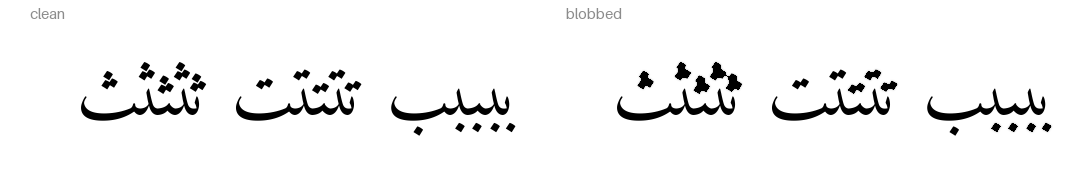

In [1]:
from textsynth import Blobify, ComponentFilter, InkBleed, Layout, Synthesizer
from nbutil import FONT, columns, sheet

TEXT = "ببببب تتتتت ثثثثث"  # beh, teh, theh: one dot, two, three
layout = Layout(size=72, supersample=2)

plain = Synthesizer(font=FONT, layout=layout)(TEXT)
blobbed = Synthesizer(font=FONT, layout=layout, effects=[Blobify(probability=1.0)], seed=2)(TEXT)
columns([("", plain, blobbed)], headings=("clean", "blobbed"), gutter=20)

## The controls

`merge_radius` sets which marks make one group. `fill_radius` closes the gap
between them. `halo` is the soft bleed around the result. `probability`
applies to each cluster.

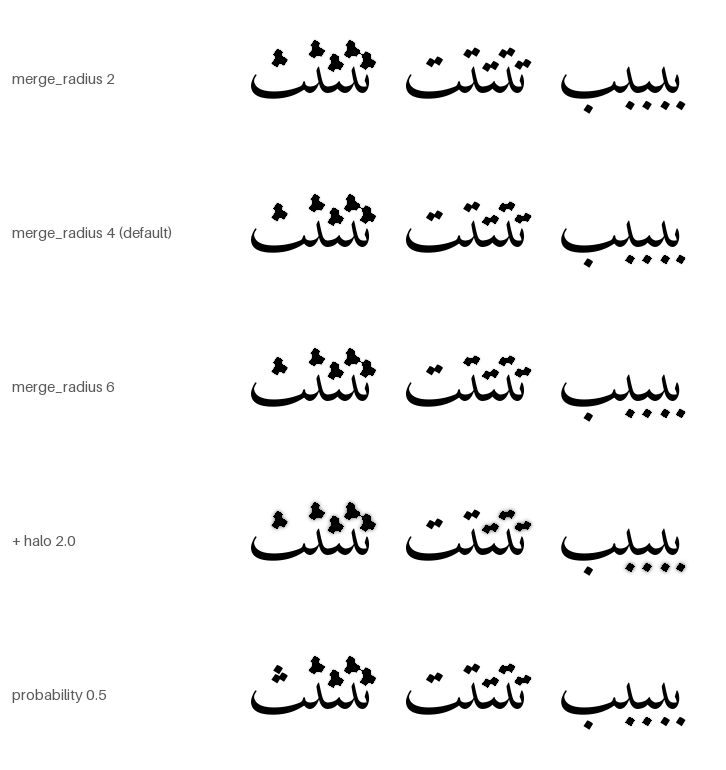

In [2]:
rows = []
for label, effect in (
    ("merge_radius 2", Blobify(merge_radius=2, probability=1.0)),
    ("merge_radius 4 (default)", Blobify(merge_radius=4, probability=1.0)),
    ("merge_radius 6", Blobify(merge_radius=6, probability=1.0)),
    ("+ halo 2.0", Blobify(merge_radius=4, halo=2.0, halo_strength=0.6, probability=1.0)),
    ("probability 0.5", Blobify(merge_radius=4, probability=0.5)),
):
    rows.append((label, Synthesizer(font=FONT, layout=layout, effects=[effect], seed=2)(TEXT)))
sheet(rows, gutter=210)

`keep_single` keeps a mark that has no neighbour. `select.max_area` keeps the
letters, which are large components.

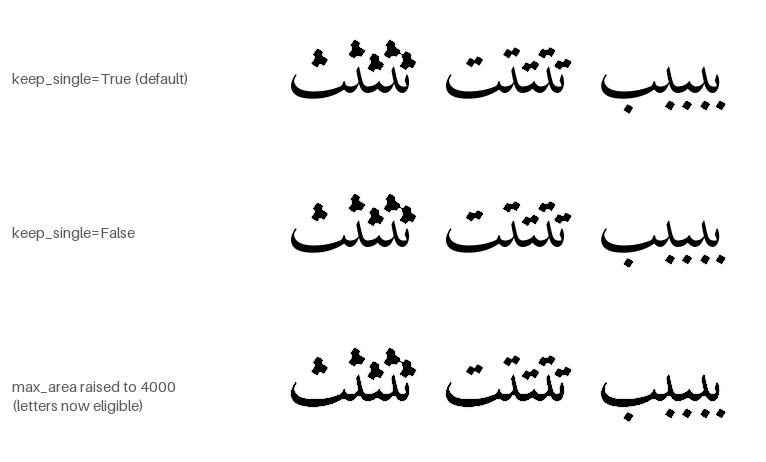

In [3]:
rows = [
    ("keep_single=True (default)", Blobify(probability=1.0)),
    ("keep_single=False", Blobify(probability=1.0, keep_single=False)),
    (
        "max_area raised to 4000\n(letters now eligible)",
        Blobify(probability=1.0, select=ComponentFilter(min_area=2, max_area=4000)),
    ),
]
sheet([(label, Synthesizer(font=FONT, layout=layout, effects=[e], seed=2)(TEXT)) for label, e in rows], gutter=250)

## In a realistic stack

Apply the bleed first and the blob second. This is the order on paper.

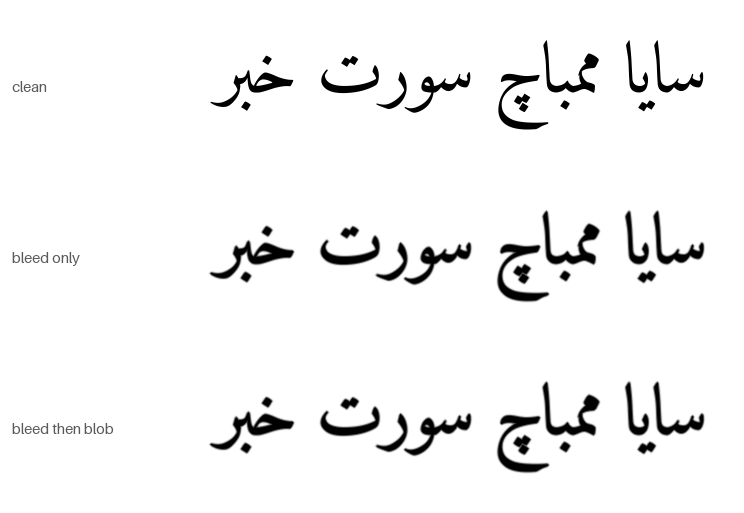

In [4]:
line = "سايا ممباچ سورت خبر"
rows = [
    ("clean", []),
    ("bleed only", [InkBleed(1.2, strength=0.8)]),
    ("bleed then blob", [InkBleed(1.2, strength=0.8), Blobify(probability=0.9)]),
]
sheet(
    [
        (label, Synthesizer(font=FONT, layout=Layout(size=72, tracking=-1, supersample=2), effects=fx, seed=5)(line))
        for label, fx in rows
    ],
    gutter=170,
)